In [ ]:
pip install qiskit qiskit-machine-learning qiskit-aer pennylane

In [2]:
!pip install qiskit_optimization
!pip install qiskit[visualization] pylatexenc
!pip install qiskit_aer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 646.5/646.5 kB 11.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 71.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 3.8 MB/s eta 0:00:00
  Created wheel for docplex: filename=docplex-2.30.251-py3-none-any.whl size=685954 sha256=5f4efef39b1f629eb8773c49d0eba5ca6888327a04d960d907ecb01dabd8bb1f
  Stored in directory: /root/.cache/pip/wheels/c1/d9/5c/1d919b1e441ebbaff244513a13d09c3c0378401601d4184bb0
Successfully built docplex
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel 

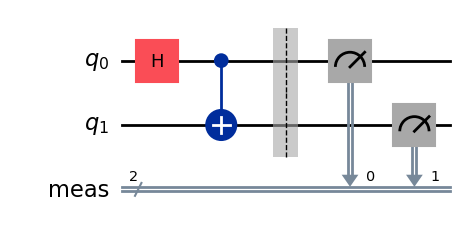

In [10]:
from qiskit import QuantumCircuit
bell_qc=QuantumCircuit(2)
bell_qc.h(0)
bell_qc.cx(0,1)
bell_qc.measure_all()
bell_qc.draw("mpl")

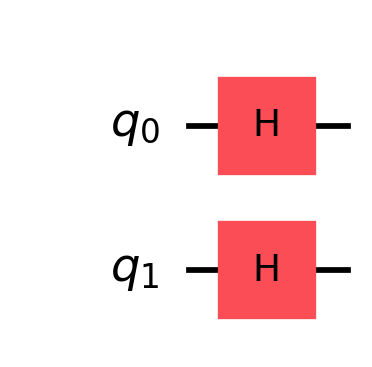

In [5]:
from qiskit import QuantumCircuit
import numpy as np
import matplotlib.pyplot as plt
qc= QuantumCircuit(2)
qc.h(0)
qc.h(1)
fig = plt.figure(figsize=(10, 10))
ax = plt.subplot(1, 2, 1)
qc.draw('mpl',ax=ax)

## GHZ-state


In [ ]:
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
simulator = Aer.get_backend('qasm_simulator')

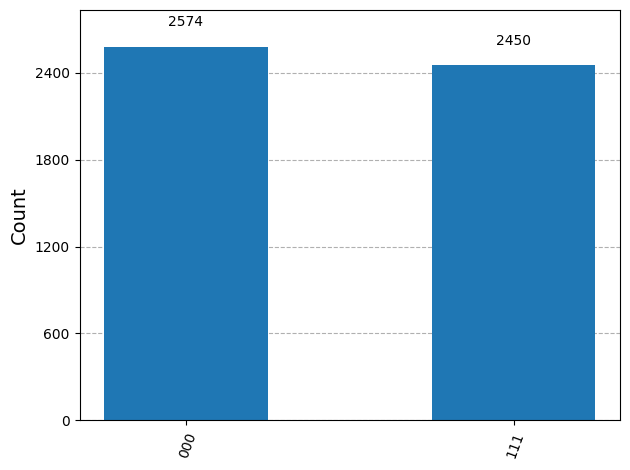

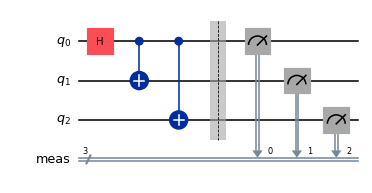

In [11]:
import matplotlib.pyplot as plt
ghz= QuantumCircuit(3)
ghz.h(0)
ghz.cx(0,1)
ghz.cx(0,2)
ghz.measure_all()
fig = plt.figure(figsize=(10, 10))
ax = plt.subplot(1, 2, 1)
qc.draw('mpl',ax=ax)
simulator = Aer.get_backend('qasm_simulator')
transpiled_circuit = transpile(ghz, simulator)
job = simulator.run(transpiled_circuit, shots=5024)
result = job.result()
counts = result.get_counts(ghz)
plot_histogram(counts)

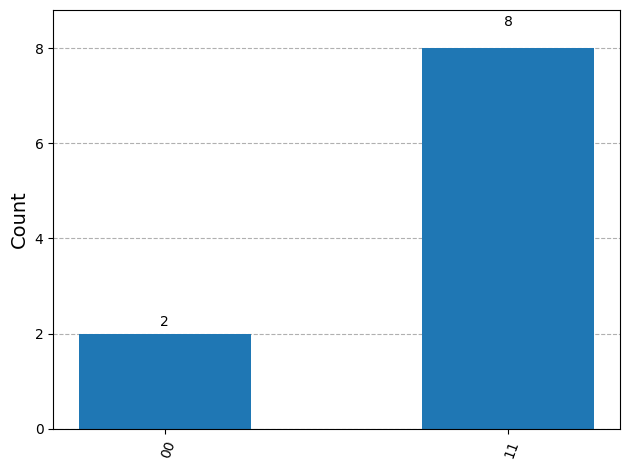

In [12]:
transpiled_circuit = transpile(bell_qc, simulator)
job = simulator.run(transpiled_circuit, shots=10)
result = job.result()
counts = result.get_counts(bell_qc)
plot_histogram(counts)

## QNN Regression

Data generated: X ∈ [-5,5], y ∈ [-1,1]


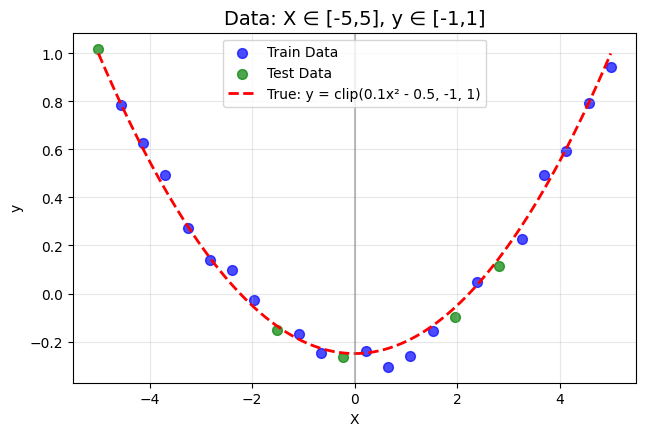

In [20]:
# ================================
# STEP 0: Imports & Generate Symmetric Data
# ================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

np.random.seed(42)

# Generate symmetric X: [-5, 5]
n_samples = 24
X = np.linspace(-5, 5, n_samples).reshape(24, 1)

# True function: parabola y = 0.1 * x² - 0.5 → at x=±5, y=2.0 → clip to [-1,1]
y_raw = 0.1 * (X.flatten()**2) - 0.5
noise = np.random.normal(0, 0.08, n_samples)
y = 1/2*(y_raw + noise)

# Clip to [-1, 1]
#y = np.clip(y, -1, 1)

# Train-test split (random, not sequential, to avoid bias)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Plot original data
plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.scatter(X_train, y_train, color='blue', label='Train Data', alpha=0.7, s=50)
plt.scatter(X_test, y_test, color='green', label='Test Data', alpha=0.7, s=50)

# True parabola (before clipping)
X_line = np.linspace(-5, 5, 200)
y_true = 1/2*np.clip(0.1 * X_line**2 - 0.5, -20, 20)
plt.plot(X_line, y_true, 'r--', linewidth=2, label='True: y = clip(0.1x² - 0.5, -1, 1)')

plt.axvline(0, color='gray', linestyle='-', alpha=0.5)  # y-axis
#plt.ylim(-20, 20)
plt.title("Data: X ∈ [-5,5], y ∈ [-1,1]", fontsize=14)
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
print("Data generated: X ∈ [-5,5], y ∈ [-1,1]")

In [ ]:
X_plot = np.linspace(-5, 5, 24).reshape(-1, 1)

[NN] MSE: 0.002


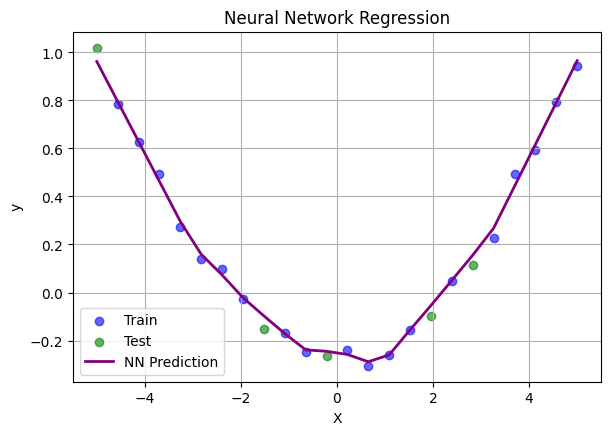

In [ ]:
# ================================
# STEP 2: PyTorch Neural Network
# ================================
import torch
import torch.nn as nn
import torch.optim as optim

# Convert to torch
X_train_t = torch.from_numpy(X_train).float()
y_train_t = torch.from_numpy(y_train).float().unsqueeze(1)
X_test_t = torch.from_numpy(X_test).float()

# Simple NN
class Regressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model = Regressor()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Train
for epoch in range(300):
    optimizer.zero_grad()
    out = model(X_train_t)
    loss = criterion(out, y_train_t)
    loss.backward()
    optimizer.step()

# Predict
model.eval()
with torch.no_grad():
    y_pred_nn = model(X_test_t).numpy().flatten()

mse_nn = mean_squared_error(y_test, y_pred_nn)
print(f"[NN] MSE: {mse_nn:.3f}")

# Plot
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 3)
plt.scatter(X_train, y_train, color='blue', label='Train', alpha=0.6)
plt.scatter(X_test, y_test, color='green', label='Test', alpha=0.6)

X_plot_t = torch.from_numpy(X_plot).float()
with torch.no_grad():
    y_plot_nn = model(X_plot_t).numpy()
plt.plot(X_plot, y_plot_nn, 'purple', label='NN Prediction', linewidth=2)
plt.title("Neural Network Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True)

## Pennylane Regression

In [14]:
# ================================
# Pennylane QNN for Parabola (Fixed Version)
# ================================
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# STEP 0: Generate Data (Parabola)
# -------------------------------
np.random.seed(42)

# 5 training points: X ∈ [-5, 5]
X = np.array([-4, -2, 0, 2, 4], dtype=float)

# True function: y = 0.5 * (0.1*x² - 0.5 + noise)
noise = np.random.normal(0, 0.08, len(X))
y_raw = 0.1 * X**2 - 0.5
Y = 0.5 * (y_raw + noise)

# 5 test points (shifted)
X_test = np.array([-4.5, -1.5, 0.5, 2.5, 4.5])
Y_test = 0.5 * (0.1 * X_test**2 - 0.5 + np.random.normal(0, 0.08, len(X_test)))

# -------------------------------
# STEP 1: Quantum Device
# -------------------------------
dev = qml.device('default.qubit', wires=2)

/usr/local/lib/python3.12/dist-packages/pennylane/__init__.py:209: RuntimeWarning: PennyLane is not yet compatible with JAX versions > 0.6.2. You have version 0.7.2 installed. Please downgrade JAX to 0.6.2 to avoid runtime errors using python -m pip install jax~=0.6.0 jaxlib~=0.6.0
  warnings.warn(


In [15]:
# STEP 2: Enhanced Quantum Circuit
# -------------------------------
@qml.qnode(dev)
def quantum_circuit(datapoint, params):
    # Scale input from [-5,5] → [0, 2π] for better coverage
    scaled_input = 2 * np.pi * (datapoint + 5) / 10.0

    # Data encoding with entanglement
    qml.RX(scaled_input, wires=0)
    qml.RY(scaled_input * 0.5, wires=1)

    # Layer 1: Variational gates
    qml.Rot(params[0], params[1], params[2], wires=0)
    qml.Rot(params[3], params[4], params[5], wires=1)
    qml.CNOT(wires=[0, 1])

    # Layer 2: More expressivity
    qml.Rot(params[6], params[7], params[8], wires=0)
    qml.Rot(params[9], params[10], params[11], wires=1)
    qml.CNOT(wires=[1, 0])

    # Measure both qubits separately and return as list
    return [qml.expval(qml.PauliZ(0)), qml.expval(qml.PauliZ(1))]

In [16]:
# STEP 3: Loss Function with Scaling
# -------------------------------
def cost_fn(params):
    predictions = []
    for x in X:
        result = quantum_circuit(x, params)
        # Combine the two qubit measurements
        combined = 0.6 * result[0] + 0.4 * result[1]
        predictions.append(combined)

    predictions = np.array(predictions)
    # Scale predictions from [-1,1] to match data range
    pred_scaled = (predictions + 1) * 0.5  # Scale to [0, 1]
    pred_scaled = pred_scaled * 2 - 0.5    # Scale to [-0.5, 1.5] approximately

    loss = np.mean((pred_scaled - Y)**2)
    return loss


In [17]:
# STEP 4: Optimizer & Training
# -------------------------------
opt = qml.AdamOptimizer(stepsize=0.1)
params = np.random.uniform(-np.pi, np.pi, 12, requires_grad=True)

print("Training Quantum Neural Network for Parabola...")
print(f"Training data range: Y ∈ [{Y.min():.3f}, {Y.max():.3f}]")
print()

costs = []
for i in range(400):
    params, cost = opt.step_and_cost(cost_fn, params)
    costs.append(cost)

    if i % 40 == 0:
        print(f"Step {i:3d} | Cost = {cost:.6f}")

print(f"\nFinal Cost: {cost:.6f}")

Training Quantum Neural Network for Parabola...
Training data range: Y ∈ [-0.224, 0.570]

Step   0 | Cost = 0.174247
Step  40 | Cost = 0.005010
Step  80 | Cost = 0.000111
Step 120 | Cost = 0.000001
Step 160 | Cost = 0.000000
Step 200 | Cost = 0.000000
Step 240 | Cost = 0.000011
Step 280 | Cost = 0.000000
Step 320 | Cost = 0.000000
Step 360 | Cost = 0.000002

Final Cost: 0.000000


In [18]:
# STEP 5: Make Predictions with Scaling
# -------------------------------
def predict(x_val, params):
    result = quantum_circuit(x_val, params)
    # Combine the two qubit measurements
    raw_pred = 0.6 * result[0] + 0.4 * result[1]
    # Apply same scaling as in cost function
    scaled = (raw_pred + 1) * 0.5
    scaled = scaled * 2 - 0.5
    return scaled

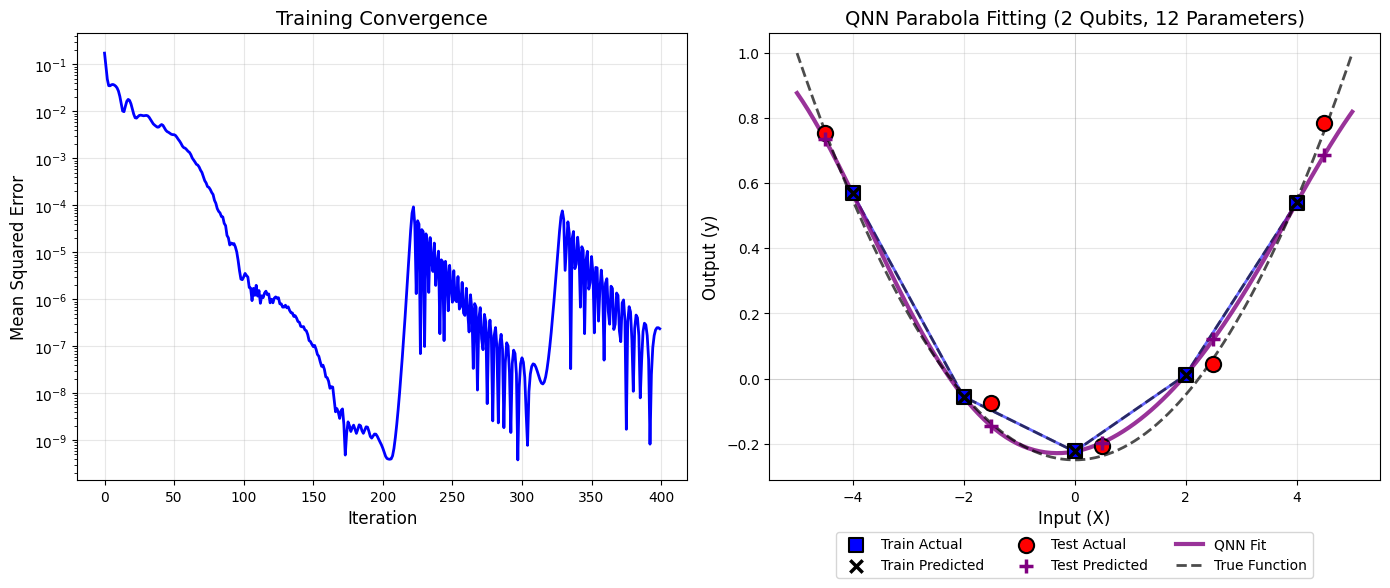


Training MSE: 0.000000
Test MSE: 0.004155


In [19]:

train_predictions = np.array([predict(x, params) for x in X])
test_predictions = np.array([predict(x, params) for x in X_test])

# -------------------------------
# STEP 6: Plot Results
# -------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left plot: Training convergence
ax1.plot(costs, color='blue', linewidth=2)
ax1.set_xlabel("Iteration", fontsize=12)
ax1.set_ylabel("Mean Squared Error", fontsize=12)
ax1.set_title("Training Convergence", fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.set_yscale('log')

# Right plot: Predictions
# Sort training data for connecting line
sorted_idx = np.argsort(X)
X_sorted = X[sorted_idx]
Y_sorted = Y[sorted_idx]
train_pred_sorted = train_predictions[sorted_idx]

# Train: Actual (blue squares + line)
ax2.scatter(X, Y, s=100, c='blue', marker='s', label='Train Actual', zorder=5, edgecolors='k', linewidth=1.5)
ax2.plot(X_sorted, Y_sorted, color='blue', linewidth=2, alpha=0.6)

# Train: Predicted (black x + line)
ax2.scatter(X_sorted, train_pred_sorted, s=80, c='black', marker='x', linewidth=2.5, label='Train Predicted', zorder=5)
ax2.plot(X_sorted, train_pred_sorted, color='black', linestyle='--', linewidth=2, alpha=0.6)

# Test: Actual (red circles)
ax2.scatter(X_test, Y_test, s=120, c='red', marker='o', label='Test Actual', zorder=5, edgecolors='k', linewidth=1.5)

# Test: Predicted (purple +)
ax2.scatter(X_test, test_predictions, s=100, c='purple', marker='+', linewidth=2.5, label='Test Predicted', zorder=5)

# Smooth QNN curve
X_dense = np.linspace(-5, 5, 200)
dense_pred = np.array([predict(x, params) for x in X_dense])
ax2.plot(X_dense, dense_pred, color='purple', linewidth=3, label='QNN Fit', alpha=0.8)

# True parabola
Y_true = 0.5 * (0.1 * X_dense**2 - 0.5)
ax2.plot(X_dense, Y_true, 'k--', linewidth=2, label='True Function', alpha=0.7)

# Styling
ax2.axhline(0, color='gray', alpha=0.3, linestyle='-', linewidth=0.5)
ax2.axvline(0, color='gray', alpha=0.3, linestyle='-', linewidth=0.5)
ax2.set_xlabel("Input (X)", fontsize=12)
ax2.set_ylabel("Output (y)", fontsize=12)
ax2.set_title("QNN Parabola Fitting (2 Qubits, 12 Parameters)", fontsize=14)
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print performance metrics
train_mse = np.mean((train_predictions - Y)**2)
test_mse = np.mean((test_predictions - Y_test)**2)
print(f"\nTraining MSE: {train_mse:.6f}")
print(f"Test MSE: {test_mse:.6f}")

In [ ]:
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
from qiskit.circuit import Parameter
from qiskit_machine_learning.circuit.library import QNNCircuit
from qiskit_machine_learning.algorithms.regressors import NeuralNetworkRegressor
from qiskit_machine_learning.optimizers import COBYLA, L_BFGS_B
from IPython.display import clear_output
from qiskit.primitives import StatevectorEstimator as Estimator
from qiskit.circuit.library import EfficientSU2
from qiskit.circuit.library import RealAmplitudes, ZZFeatureMap
from qiskit import QuantumCircuit
estimator = Estimator()
feature_map = ZZFeatureMap(3)

In [ ]:
# construct simple feature map
param_x = Parameter("x")
feature_map = QuantumCircuit(1, name="fm")
feature_map.ry(param_x, 0)

# construct simple ansatz
param_y = Parameter("y")
ansatz = QuantumCircuit(1, name="vf")
ansatz.ry(param_y, 0)

#ansatz=EfficientSU2(1,reps=20)
# construct a circuit
qc = QNNCircuit(feature_map=feature_map, ansatz=ansatz)

# construct QNN
regression_estimator_qnn = EstimatorQNN(circuit=qc, estimator=estimator)

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


In [ ]:
def callback_graph(weights, obj_func_eval):
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    print(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

In [ ]:
regressor = NeuralNetworkRegressor(
    neural_network=regression_estimator_qnn,
    loss="squared_error",
    optimizer=L_BFGS_B(maxiter=400),
    callback=callback_graph,
)

0.3479564053256352


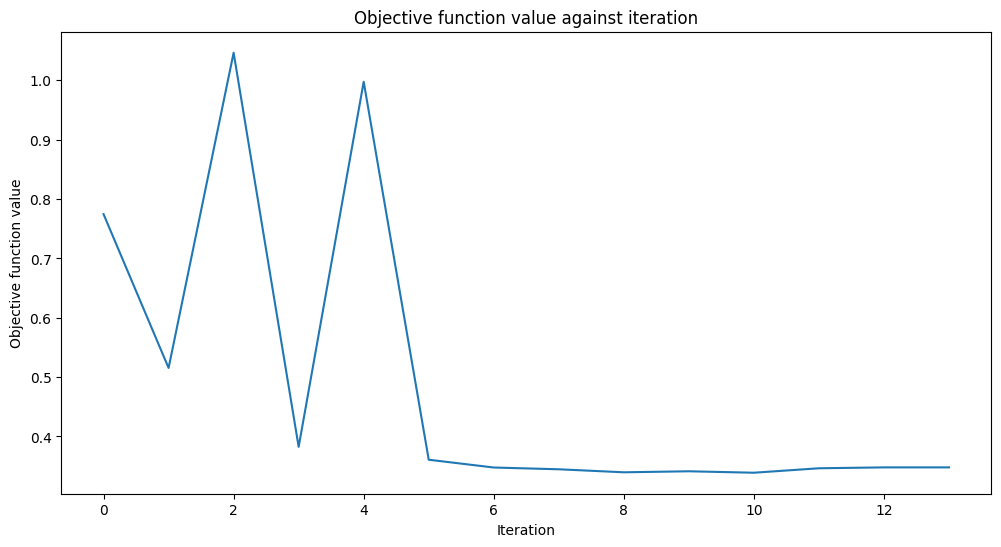

-1.2228306172805476

In [ ]:
# create empty array for callback to store evaluations of the objective function
objective_func_vals = []
plt.rcParams["figure.figsize"] = (12, 6)

# fit to data
regressor.fit(X_train, y_train)

# return to default figsize
plt.rcParams["figure.figsize"] = (6, 4)

# score the result
regressor.score(X_train, y_train)

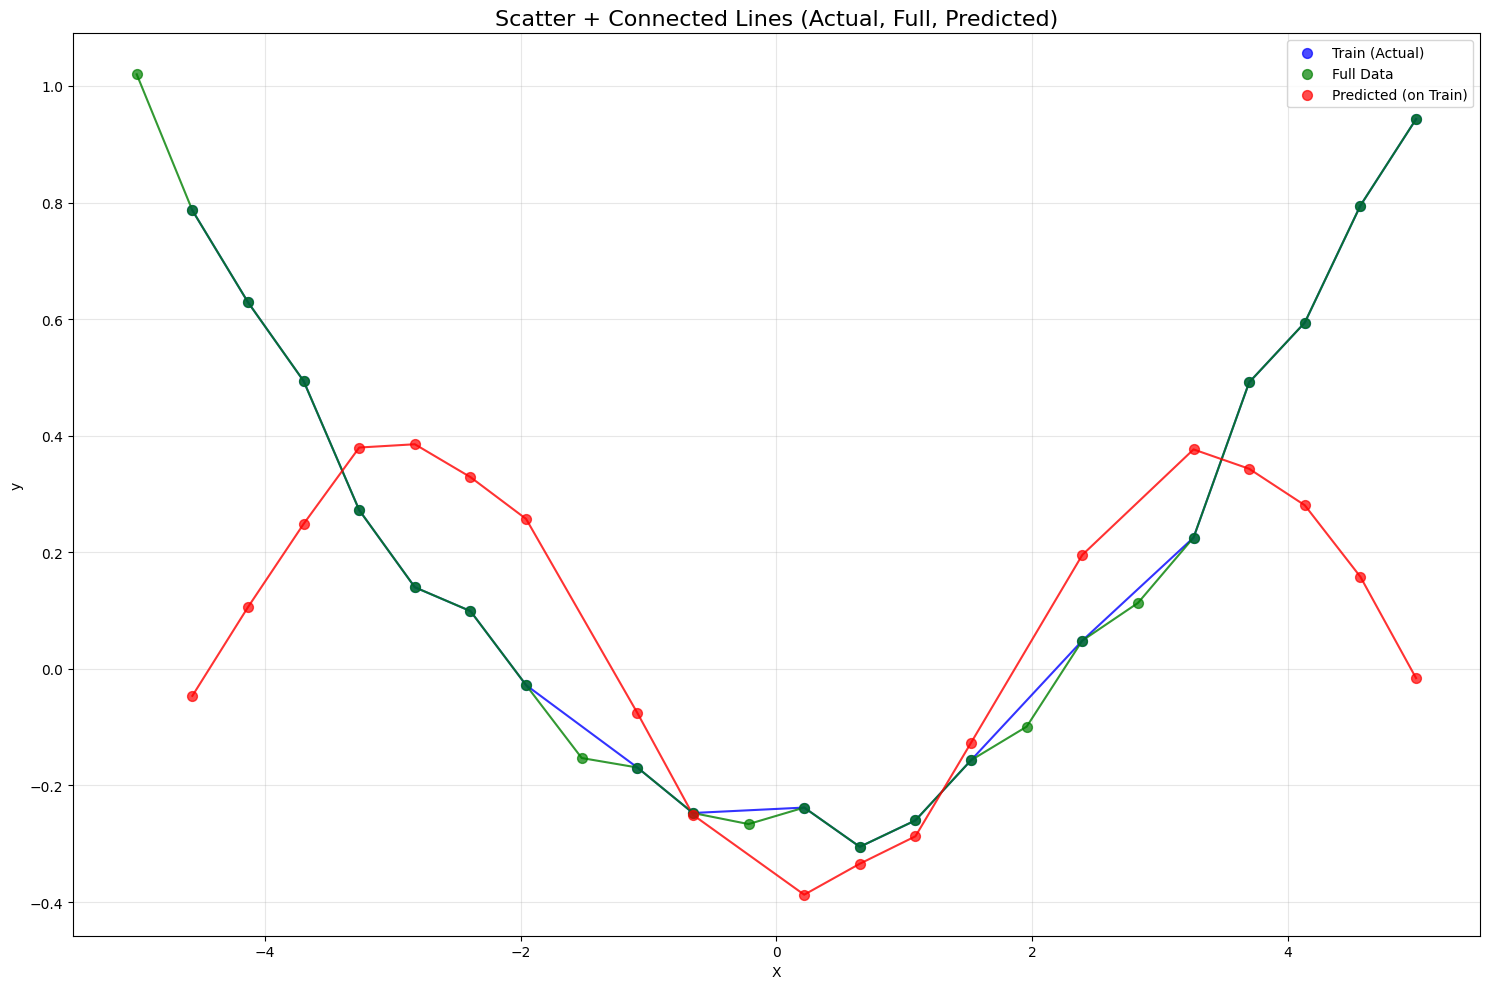

In [ ]:
# plot target function
plt.figure(figsize=(15, 10))

# 1. Train data (actual) - Blue points + connecting line
sorted_idx_train = np.argsort(X_train.flatten())
X_train_sorted = X_train[sorted_idx_train]
y_train_sorted = y_train[sorted_idx_train]

plt.scatter(X_train, y_train, color='blue', label='Train (Actual)', alpha=0.7, s=50, zorder=5)
plt.plot(X_train_sorted, y_train_sorted, color='blue', linestyle='-', linewidth=1.5, alpha=0.8, label='_nolegend_')

# 2. Full data - Green points + connecting line
sorted_idx_full = np.argsort(X.flatten())
X_sorted = X[sorted_idx_full]
y_sorted = y[sorted_idx_full]

plt.scatter(X, y, color='green', label='Full Data', alpha=0.7, s=50, zorder=5)
plt.plot(X_sorted, y_sorted, color='green', linestyle='-', linewidth=1.5, alpha=0.8, label='_nolegend_')

# 3. Predictions on train - Red points + connecting line
y_pred_train = regressor.predict(X_train)
sorted_idx_pred = np.argsort(X_train.flatten())
X_pred_sorted = X_train[sorted_idx_pred]
y_pred_sorted = y_pred_train[sorted_idx_pred]

plt.scatter(X_train, y_pred_train, color='red', label='Predicted (on Train)', alpha=0.7, s=50, zorder=5)
plt.plot(X_pred_sorted, y_pred_sorted, color='red', linestyle='-', linewidth=1.5, alpha=0.8, label='_nolegend_')

# Styling
plt.title("Scatter + Connected Lines (Actual, Full, Predicted)", fontsize=16)
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()